# Ablation V4 — CNN + GAT + GCN (concat fusion, NO SE gate)

## Prostate Cancer Detection · H&E Histopathology (DiagSet Binary)

**Journal Retrain — matched to Hybrid / LGCN / GAT / JGCN retrain protocol**

Purpose of V4: measure the effect of **removing only the SE fusion gate** from the proposed Hybrid model. Architecturally identical to Hybrid v5 in every respect except the fusion strategy: V4 uses plain concatenation, V5 uses the SE-gated concatenation. V4 vs V5 (the Hybrid) isolates the effect of adaptive branch re-weighting from the effect of having all three branches present.

- **Architecture**: EfficientNet-B4 (blocks 0-4 frozen) → cnn_proj (1792 → 512) + batch-level GAT (2 layers × 4 heads, hidden 256) + 3-layer SLIC-graph GCN (8 → 256 → 128 → 64) → concat (512 + 256 + 64 = 832) → classifier (832 → 512 → 128 → 2)
- **All three branches present. No SE fusion gate.**
- **Graph cache**: reuses Hybrid's `<repo>/cache\graph_cache.pkl`
- **Local paths**: `<repo>/results\Ablation_V4\`
- **Environment**: `abide` conda env (torch 2.5.1+cu121, PyG 2.8.0, CUDA 12.1)
- **Hardware**: RTX 3060 12 GB

**Matched protocol vs V1 / V2 / V3 / Hybrid / LGCN / GAT / JGCN**
- 80 epochs, patience 15 on validation AUC-ROC
- Focal Loss (γ=2.0, α=0.75)
- AdamW differential LRs (backbone 1×10⁻⁴, head 3×10⁻⁴), weight decay 1×10⁻⁴
- CosineAnnealingWarmRestarts (T₀=10, T_mult=2)
- MixUp α=0.2 on 50% of batches, TrivialAugment, RandomErasing p=0.25
- WeightedRandomSampler, TTA×5 at inference (fp32)
- seed=42, image-level 70/15/15 stratified split (identical 901-patch test set)

**Artefacts produced (Cell 6B)**
- `v4_predictions.npz` — y_true / y_pred / y_prob (non-TTA & TTA) + 832-dim fused features
- `v4_history.json` — full epoch-by-epoch metrics
- `v4_env.json` — reproducibility fingerprint
- `checkpoints_backup/` — local copy of all four artefacts

**Bug fixes carried over (from V1/V2/V3)**
- Val-loop lists renamed `v_probs, v_labels` (no dataset-array collision)
- Cell 6 reads test paths/labels from `test_ds` attributes directly

**Direct V4 vs V5 comparison in §3**
- Same architecture except SE gate → V4 - V5 accuracy delta *is* the SE gate's contribution
- Same graph cache, same training data, same seed → any difference is purely due to SE gating


## CELL 1B — Local PC Setup

In [ ]:
# Resolve the repository root so this notebook runs from a clean clone.
import os
REPO_ROOT = os.getcwd()
while not os.path.exists(os.path.join(REPO_ROOT, 'config.py')):
    parent = os.path.dirname(REPO_ROOT)
    if parent == REPO_ROOT:
        raise RuntimeError('config.py not found - run this notebook from inside the repository')
    REPO_ROOT = parent
print('REPO_ROOT:', REPO_ROOT)


In [1]:
# ╔══════════════════════════════════════════════════════════════╗
# ║ CELL 1B — Local PC Setup                                     ║
# ╚══════════════════════════════════════════════════════════════╝
import os

WORK_DIR   = os.path.join(REPO_ROOT, 'runs', 'ablation_v4')
DATA_ROOT  = REPO_ROOT
DRIVE_ROOT = DATA_ROOT

os.makedirs(WORK_DIR, exist_ok=True)
assert os.path.isdir(WORK_DIR), f'Folder not found: {WORK_DIR}'

print('Work directory  :', WORK_DIR)
print('Files in folder :')
for f in sorted(os.listdir(WORK_DIR)):
    print('  •', f)


Work directory  : <repo>/results\Ablation_V4
Files in folder :
  • checkpoints_backup


## CELL 1 — Environment check

In [2]:
# ╔══════════════════════════════════════════════════════════════╗
# ║ CELL 1 — Environment check                                   ║
# ║   V4 needs PyG (GATConv + GCNConv)                           ║
# ╚══════════════════════════════════════════════════════════════╝
import torch, sys
print('Python  :', sys.version.split()[0])
print('Torch   :', torch.__version__)
print('CUDA    :', torch.version.cuda)
print('GPU     :', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'cpu')
import torchvision, timm, torch_geometric
print('torchvision     :', torchvision.__version__)
print('timm            :', timm.__version__)
print('torch_geometric :', torch_geometric.__version__)


Python  : 3.10.20
Torch   : 2.5.1+cu121
CUDA    : 12.1
GPU     : NVIDIA GeForce RTX 3060
torchvision     : 0.20.1+cu121
timm            : 1.0.9
torch_geometric : 2.5.3


## CELL 2 — Imports and Config (LOCAL paths)

In [3]:
# ╔══════════════════════════════════════════════════════════════╗
# ║ CELL 2 — Imports and Config                                  ║
# ║   V4 architecture: CNN + GAT (batch) + GCN (SLIC), concat    ║
# ║   NO SE fusion gate                                          ║
# ╚══════════════════════════════════════════════════════════════╝
import os, random, warnings, pickle, time, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from tqdm import tqdm
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
import torchvision.transforms as T
import timm

from torch_geometric.nn import GATConv, GCNConv, global_mean_pool
from torch_geometric.data import Data, Batch

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, f1_score, precision_score, recall_score,
    roc_auc_score, confusion_matrix, classification_report,
    matthews_corrcoef, roc_curve, precision_recall_curve, average_precision_score
)
warnings.filterwarnings('ignore')

def denormalize(img_tensor):
    mean = np.array([0.485, 0.456, 0.406])
    std  = np.array([0.229, 0.224, 0.225])
    img  = img_tensor.cpu().numpy().transpose(1, 2, 0)
    return np.clip(img * std + mean, 0, 1)

CONFIG = {
    # ── LOCAL PATHS ──
    'data_dir'         : os.path.join(REPO_ROOT, 'dataset'),
    'output_dir'       : WORK_DIR,
    'graph_cache_path' : os.path.join(REPO_ROOT, 'cache', 'graph_cache.pkl'),
    'model_save_path'  : os.path.join(WORK_DIR, 'best_v4_model.pth'),

    # ── Image ──
    'img_size'         : 224,

    # ── V4 architecture (matches Hybrid exactly except NO SE gate) ──
    'cnn_proj_dim'     : 512,
    'gat_hidden_dim'   : 256,
    'gat_heads'        : 4,
    'gat_dropout'      : 0.2,
    'gcn_hidden_dim'   : 256,
    'gcn_node_in_dim'  : 8,
    'head_hidden_dim'  : 128,
    'dropout'          : 0.4,
    'num_classes'      : 2,

    # ── Training (MATCHED) ──
    'batch_size'       : 32,
    'num_epochs'       : 80,
    'lr_backbone'      : 1e-4,
    'lr_head'          : 3e-4,
    'weight_decay'     : 1e-4,
    'patience'         : 15,
    'focal_gamma'      : 2.0,
    'focal_alpha'      : 0.75,
    'seed'             : 42,
    'train_split'      : 0.70,
    'val_split'        : 0.15,
    'test_split'       : 0.15,
    'num_workers'      : 0,
    'mixup_alpha'      : 0.2,
    'mixup_prob'       : 0.5,
    'erase_prob'       : 0.25,
    'tta_n'            : 5,
    'use_amp'          : False,
}
SEED = CONFIG['seed']
MODEL_PATH = CONFIG['model_save_path']

def set_seed(s):
    random.seed(s); np.random.seed(s)
    torch.manual_seed(s); torch.cuda.manual_seed_all(s)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(SEED)
os.makedirs(CONFIG['output_dir'], exist_ok=True)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

print('=' * 60)
print('  ABLATION V4: CNN + GAT + GCN (concat, NO SE gate)')
print('  Journal Retrain — matched protocol')
print('=' * 60)
print(f'  Device      : {DEVICE}')
if torch.cuda.is_available():
    print(f'  GPU         : {torch.cuda.get_device_name(0)}')
print(f'  Epochs      : {CONFIG["num_epochs"]}  |  Patience : {CONFIG["patience"]}')
print(f'  GAT         : 2 layers × {CONFIG["gat_heads"]} heads, hidden {CONFIG["gat_hidden_dim"]}')
print(f'  GCN         : 3-layer, hidden {CONFIG["gcn_hidden_dim"]} -> 128 -> 64')
print(f'  Fusion      : concat (512 + 256 + 64 = 832)   -- NO SE gate')
print(f'  Graph cache : {CONFIG["graph_cache_path"]}')
print(f'  Model out   : {CONFIG["model_save_path"]}')
print('=' * 60)


  ABLATION V4: CNN + GAT + GCN (concat, NO SE gate)
  Journal Retrain — matched protocol
  Device      : cuda
  GPU         : NVIDIA GeForce RTX 3060
  Epochs      : 80  |  Patience : 15
  GAT         : 2 layers × 4 heads, hidden 256
  GCN         : 3-layer, hidden 256 -> 128 -> 64
  Fusion      : concat (512 + 256 + 64 = 832)   -- NO SE gate
  Graph cache : <repo>/cache\graph_cache.pkl
  Model out   : <repo>/results\Ablation_V4\best_v4_model.pth


## CELL 3 — Dataset (with SLIC graphs) + Split + Loaders

In [4]:
# ╔══════════════════════════════════════════════════════════════╗
# ║ CELL 3 — Dataset + Split + Loaders (graph-aware, same as V3) ║
# ╚══════════════════════════════════════════════════════════════╝
IMG_EXTS = {'.jpg', '.jpeg', '.png', '.bmp'}

print(f'Loading graph cache from: {CONFIG["graph_cache_path"]}')
with open(CONFIG['graph_cache_path'], 'rb') as f:
    graph_cache = pickle.load(f)
print(f'  Loaded {len(graph_cache):,} cached graphs')
sample_key = next(iter(graph_cache))
sample_val = graph_cache[sample_key]
print(f'  Sample keys : {list(sample_val.keys())}')
print(f'  x.shape     : {np.asarray(sample_val["x"]).shape}   (expected [n_nodes, 8])')
print(f'  ei.shape    : {np.asarray(sample_val["edge_index"]).shape}   (expected [2, ~n_nodes*k])')

class ProstateHybridDataset(Dataset):
    def __init__(self, file_list, labels, transform, graph_cache):
        self.file_list   = file_list
        self.labels      = labels
        self.transform   = transform
        self.graph_cache = graph_cache
    def __len__(self):
        return len(self.file_list)
    def __getitem__(self, idx):
        p     = self.file_list[idx]
        label = int(self.labels[idx])
        img_t = self.transform(Image.open(p).convert('RGB'))
        cached = self.graph_cache.get(p)
        if cached is not None:
            graph = Data(
                x=torch.tensor(cached['x'], dtype=torch.float),
                edge_index=torch.tensor(cached['edge_index'], dtype=torch.long),
                y=torch.tensor(label, dtype=torch.long),
            )
        else:
            graph = None
        return img_t, torch.tensor(label, dtype=torch.long), graph

def collate_fn(batch):
    imgs   = torch.stack([b[0] for b in batch])
    labels = torch.stack([b[1] for b in batch])
    graphs = [b[2] for b in batch if b[2] is not None]
    gbatch = Batch.from_data_list(graphs) if graphs else None
    return imgs, labels, gbatch

data_dir = Path(CONFIG['data_dir'])
all_paths, all_labels = [], []
for label_idx, cls in enumerate(['Benign', 'Malignant']):
    class_dir = data_dir / cls
    files = [pp for pp in class_dir.iterdir() if pp.suffix.lower() in IMG_EXTS]
    all_paths.extend([str(pp) for pp in files])
    all_labels.extend([label_idx] * len(files))
    print(f'  {cls:12s}: {len(files):5d} images')

all_paths  = np.array(all_paths)
all_labels = np.array(all_labels)
print(f'  Total       : {len(all_paths)}')

idx = np.arange(len(all_paths))
train_idx, temp_idx = train_test_split(
    idx, test_size=0.30, stratify=all_labels, random_state=SEED)
val_idx, test_idx   = train_test_split(
    temp_idx, test_size=0.50,
    stratify=all_labels[temp_idx], random_state=SEED)
print(f'  Train : {len(train_idx)}   Val : {len(val_idx)}   Test : {len(test_idx)}')

def hit_rate(paths):
    return sum(1 for p in paths if p in graph_cache) / max(1, len(paths))
print(f'  Graph-cache hit rate: '
      f'train {hit_rate(all_paths[train_idx])*100:.1f}%  '
      f'val {hit_rate(all_paths[val_idx])*100:.1f}%  '
      f'test {hit_rate(all_paths[test_idx])*100:.1f}%')

train_tf = T.Compose([
    T.Resize((CONFIG['img_size'], CONFIG['img_size'])),
    T.RandomHorizontalFlip(),
    T.RandomVerticalFlip(),
    T.RandomRotation(15),
    T.TrivialAugmentWide(),
    T.ToTensor(),
    T.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
    T.RandomErasing(p=CONFIG['erase_prob'], scale=(0.02, 0.10), ratio=(0.3, 3.3)),
])
eval_tf = T.Compose([
    T.Resize((CONFIG['img_size'], CONFIG['img_size'])),
    T.ToTensor(),
    T.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

class TTAWrap:
    def __init__(self, base_tf):
        self.base = base_tf
    def __call__(self, img):
        return [
            self.base(img),
            self.base(img.transpose(Image.FLIP_LEFT_RIGHT)),
            self.base(img.transpose(Image.FLIP_TOP_BOTTOM)),
            self.base(img.rotate(90)),
            self.base(img.rotate(270)),
        ]
tta_tf = TTAWrap(eval_tf)

train_ds = ProstateHybridDataset(all_paths[train_idx].tolist(),
                                  all_labels[train_idx].tolist(),
                                  train_tf, graph_cache)
val_ds   = ProstateHybridDataset(all_paths[val_idx].tolist(),
                                  all_labels[val_idx].tolist(),
                                  eval_tf, graph_cache)
test_ds  = ProstateHybridDataset(all_paths[test_idx].tolist(),
                                  all_labels[test_idx].tolist(),
                                  eval_tf, graph_cache)

train_labels_arr = all_labels[train_idx]
class_counts = np.bincount(train_labels_arr, minlength=2)
class_weights = 1.0 / class_counts
sample_weights = class_weights[train_labels_arr]
train_sampler = WeightedRandomSampler(
    weights=torch.DoubleTensor(sample_weights),
    num_samples=len(sample_weights),
    replacement=True)

train_loader = DataLoader(train_ds, batch_size=CONFIG['batch_size'],
                           sampler=train_sampler, num_workers=CONFIG['num_workers'],
                           collate_fn=collate_fn)
val_loader   = DataLoader(val_ds,   batch_size=CONFIG['batch_size'],
                           shuffle=False, num_workers=CONFIG['num_workers'],
                           collate_fn=collate_fn)
test_loader  = DataLoader(test_ds,  batch_size=CONFIG['batch_size'],
                           shuffle=False, num_workers=CONFIG['num_workers'],
                           collate_fn=collate_fn)

print(f'  Train sampler: WeightedRandomSampler (inverse class frequency)')
print(f'  Class counts : {dict(zip(["Benign","Malignant"], class_counts.tolist()))}')


Loading graph cache from: <repo>/cache\graph_cache.pkl
  Loaded 6,002 cached graphs
  Sample keys : ['x', 'edge_index']
  x.shape     : (71, 8)   (expected [n_nodes, 8])
  ei.shape    : (2, 410)   (expected [2, ~n_nodes*k])
  Benign      :  3000 images
  Malignant   :  3002 images
  Total       : 6002
  Train : 4201   Val : 900   Test : 901
  Graph-cache hit rate: train 100.0%  val 100.0%  test 100.0%
  Train sampler: WeightedRandomSampler (inverse class frequency)
  Class counts : {'Benign': 2100, 'Malignant': 2101}


## CELL 4 — V4 Model Architecture (CNN + GAT + GCN, concat, NO SE)

In [5]:
# ╔══════════════════════════════════════════════════════════════╗
# ║ CELL 4 — V4 Model                                            ║
# ║   Identical to Hybrid EXCEPT no SE fusion gate               ║
# ║   Direct V4 vs V5 comparison = pure SE gate effect           ║
# ╚══════════════════════════════════════════════════════════════╝
class CNN_GAT_GCN_NoSE_Classifier(nn.Module):
    def __init__(self, num_classes=2, proj_dim=512,
                 gat_hidden=256, gat_heads=4, gat_dropout=0.2,
                 gcn_hidden=256, gcn_node_in=8,
                 head_dim=128, dropout=0.4):
        super().__init__()
        Hg  = gat_hidden       # 256
        Hgc = gcn_hidden       # 256

        # Backbone
        self.backbone = timm.create_model('efficientnet_b4', pretrained=True,
                                           num_classes=0, global_pool='avg')
        cnn_dim = self.backbone.num_features  # 1792

        blocks_to_freeze = ['blocks.0', 'blocks.1', 'blocks.2', 'blocks.3',
                            'conv_stem', 'bn1']
        for name, param in self.backbone.named_parameters():
            if any(b in name for b in blocks_to_freeze):
                param.requires_grad = False

        # CNN projection (identical to Hybrid / V1 / V2 / V3)
        self.cnn_proj = nn.Sequential(
            nn.Linear(cnn_dim, proj_dim),
            nn.BatchNorm1d(proj_dim),
            nn.ReLU(),
            nn.Dropout(dropout * 0.5))

        # GAT branch (identical to Hybrid GAT branch)
        self.gat_node_proj = nn.Sequential(nn.Linear(cnn_dim, Hg), nn.ReLU())
        self.gat1 = GATConv(Hg, Hg // gat_heads, heads=gat_heads, dropout=gat_dropout)
        self.gat2 = GATConv(Hg, Hg // gat_heads, heads=gat_heads, dropout=gat_dropout)
        self.gat_norm1 = nn.LayerNorm(Hg)
        self.gat_norm2 = nn.LayerNorm(Hg)

        # GCN branch (identical to Hybrid GCN branch)
        self.gcn_input_proj = nn.Sequential(nn.Linear(gcn_node_in, Hgc), nn.ReLU())
        self.gcn1 = GCNConv(Hgc,       Hgc)
        self.gcn2 = GCNConv(Hgc,       Hgc // 2)
        self.gcn3 = GCNConv(Hgc // 2,  Hgc // 4)
        self.gcn_norm1 = nn.LayerNorm(Hgc)
        self.gcn_norm2 = nn.LayerNorm(Hgc // 2)
        self.gcn_norm3 = nn.LayerNorm(Hgc // 4)

        # Fusion: PLAIN CONCAT — no SE gate
        gcn_out_dim = Hgc // 4   # 64
        fusion_dim  = proj_dim + Hg + gcn_out_dim   # 512 + 256 + 64 = 832

        # Classifier — identical to Hybrid
        self.classifier = nn.Sequential(
            nn.Linear(fusion_dim, proj_dim),
            nn.BatchNorm1d(proj_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(proj_dim, head_dim),
            nn.BatchNorm1d(head_dim),
            nn.ReLU(),
            nn.Dropout(dropout * 0.6),
            nn.Linear(head_dim, num_classes))

        self._gcn_out_dim = gcn_out_dim

    def forward(self, imgs, graph_batch):
        B = imgs.size(0)
        cnn_feats = self.backbone(imgs)           # (B, 1792)
        cnn_out   = self.cnn_proj(cnn_feats)      # (B, 512)

        # ── GAT: dynamic fully-connected batch graph, no self-loops ──
        gat_nodes = self.gat_node_proj(cnn_feats)  # (B, 256)
        src = torch.arange(B, device=imgs.device).repeat_interleave(B)
        dst = torch.arange(B, device=imgs.device).repeat(B)
        mask = src != dst
        ei_gat = torch.stack([src[mask], dst[mask]])
        bv_gat = torch.arange(B, device=imgs.device)
        x = self.gat_norm1(F.elu(self.gat1(gat_nodes, ei_gat)))
        x = self.gat_norm2(F.elu(self.gat2(x, ei_gat)))
        gat_out = global_mean_pool(x, bv_gat)      # (B, 256)

        # ── GCN: SLIC superpixel graph (pre-cached) ─────────────────
        if graph_batch is not None:
            gx = self.gcn_input_proj(graph_batch.x)
            ei = graph_batch.edge_index
            gb = graph_batch.batch
            gx = self.gcn_norm1(F.relu(self.gcn1(gx, ei)))
            gx = self.gcn_norm2(F.relu(self.gcn2(gx, ei)))
            gx = self.gcn_norm3(F.relu(self.gcn3(gx, ei)))
            gcn_out = global_mean_pool(gx, gb)     # (B, 64)
        else:
            gcn_out = torch.zeros(B, self._gcn_out_dim, device=imgs.device)

        # ── Plain concat fusion (NO SE gate) ─────────────────────────
        fused = torch.cat([cnn_out, gat_out, gcn_out], dim=1)   # (B, 832)
        return self.classifier(fused)

model = CNN_GAT_GCN_NoSE_Classifier(
    num_classes=CONFIG['num_classes'],
    proj_dim=CONFIG['cnn_proj_dim'],
    gat_hidden=CONFIG['gat_hidden_dim'],
    gat_heads=CONFIG['gat_heads'],
    gat_dropout=CONFIG['gat_dropout'],
    gcn_hidden=CONFIG['gcn_hidden_dim'],
    gcn_node_in=CONFIG['gcn_node_in_dim'],
    head_dim=CONFIG['head_hidden_dim'],
    dropout=CONFIG['dropout']).to(DEVICE)

n_total = sum(p.numel() for p in model.parameters())
n_train = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'  Total params    : {n_total:,}')
print(f'  Trainable params: {n_train:,}  ({100*n_train/n_total:.1f}%)')
print(f'  CNN freeze depth: blocks 0-4  (matched)')
print(f'  Fusion          : concat 512 + 256 + 64 = 832   (NO SE gate)')


  Total params    : 19,664,138
  Trainable params: 18,290,526  (93.0%)
  CNN freeze depth: blocks 0-4  (matched)
  Fusion          : concat 512 + 256 + 64 = 832   (NO SE gate)


## CELL 5 — Training Loop

In [6]:
# ╔══════════════════════════════════════════════════════════════╗
# ║ CELL 5 — Training Loop                                       ║
# ║   Val lists renamed v_probs / v_labels (no collision)        ║
# ╚══════════════════════════════════════════════════════════════╝
class FocalLoss(nn.Module):
    def __init__(self, gamma=2.0, alpha=0.75):
        super().__init__()
        self.gamma = gamma
        self.alpha = alpha
    def forward(self, logits, targets):
        ce = F.cross_entropy(logits, targets, reduction='none')
        pt = torch.exp(-ce)
        alpha_t = torch.where(targets == 1, self.alpha, 1 - self.alpha)
        loss = alpha_t * (1 - pt) ** self.gamma * ce
        return loss.mean()

def mixup_batch(imgs, labels, alpha=0.2):
    lam = np.random.beta(alpha, alpha)
    idx_perm = torch.randperm(imgs.size(0), device=imgs.device)
    mixed_imgs = lam * imgs + (1 - lam) * imgs[idx_perm]
    labels_a, labels_b = labels, labels[idx_perm]
    return mixed_imgs, labels_a, labels_b, lam

def mixup_focal(criterion, logits, labels_a, labels_b, lam):
    return lam * criterion(logits, labels_a) + (1 - lam) * criterion(logits, labels_b)

backbone_params = [p for n, p in model.named_parameters()
                   if 'backbone' in n and p.requires_grad]
head_params     = [p for n, p in model.named_parameters()
                   if 'backbone' not in n and p.requires_grad]
optimizer = torch.optim.AdamW([
    {'params': backbone_params, 'lr': CONFIG['lr_backbone']},
    {'params': head_params,     'lr': CONFIG['lr_head']},
], weight_decay=CONFIG['weight_decay'])

scheduler = torch.optim.lr_scheduler.CosineAnnealingWarmRestarts(
    optimizer, T_0=10, T_mult=2, eta_min=1e-6)

criterion = FocalLoss(gamma=CONFIG['focal_gamma'], alpha=CONFIG['focal_alpha'])

history = {'train_loss': [], 'train_acc': [],
           'val_loss': [], 'val_acc': [], 'val_auc': []}
best_val_auc = 0.0
best_val_acc = 0.0
best_epoch   = 0
patience_ctr = 0

os.makedirs(os.path.dirname(MODEL_PATH), exist_ok=True)
BACKUP_DIR = os.path.join(WORK_DIR, 'checkpoints_backup')
os.makedirs(BACKUP_DIR, exist_ok=True)

print(f'\nTraining V4 for {CONFIG["num_epochs"]} epochs (patience={CONFIG["patience"]})...')
t_start = time.time()

for epoch in range(1, CONFIG['num_epochs'] + 1):
    model.train()
    tr_loss_sum, tr_correct, tr_total = 0.0, 0, 0
    for imgs, labels, gbatch in train_loader:
        imgs   = imgs.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)
        if gbatch is not None:
            gbatch = gbatch.to(DEVICE)

        use_mixup = np.random.rand() < CONFIG['mixup_prob']
        if use_mixup:
            imgs, la, lb, lam = mixup_batch(imgs, labels, CONFIG['mixup_alpha'])

        optimizer.zero_grad()
        out = model(imgs, gbatch)
        loss = mixup_focal(criterion, out, la, lb, lam) if use_mixup \
               else criterion(out, labels)
        loss.backward()
        optimizer.step()

        tr_loss_sum += loss.item() * imgs.size(0)
        preds = out.argmax(dim=1)
        tr_correct += (preds == (la if use_mixup else labels)).sum().item()
        tr_total   += imgs.size(0)

    scheduler.step()
    train_loss = tr_loss_sum / tr_total
    train_acc  = tr_correct  / tr_total

    model.eval()
    val_loss_sum, val_correct, val_total = 0.0, 0, 0
    v_probs, v_labels = [], []
    with torch.no_grad():
        for imgs, labels, gbatch in val_loader:
            imgs   = imgs.to(DEVICE, non_blocking=True)
            labels = labels.to(DEVICE, non_blocking=True)
            if gbatch is not None:
                gbatch = gbatch.to(DEVICE)
            out = model(imgs, gbatch)
            loss = criterion(out, labels)
            val_loss_sum += loss.item() * imgs.size(0)
            probs = torch.softmax(out.float(), dim=1)[:, 1]
            preds = out.argmax(dim=1)
            val_correct += (preds == labels).sum().item()
            val_total   += imgs.size(0)
            v_probs.extend(probs.cpu().numpy().tolist())
            v_labels.extend(labels.cpu().numpy().tolist())

    val_loss = val_loss_sum / val_total
    val_acc  = val_correct  / val_total
    try:
        val_auc = roc_auc_score(v_labels, v_probs)
    except Exception:
        val_auc = float('nan')

    history['train_loss'].append(train_loss)
    history['train_acc'].append(train_acc)
    history['val_loss'].append(val_loss)
    history['val_acc'].append(val_acc)
    history['val_auc'].append(val_auc)

    marker = ''
    if val_auc > best_val_auc:
        best_val_auc = val_auc
        best_val_acc = val_acc
        best_epoch   = epoch
        patience_ctr = 0
        torch.save({
            'model': model.state_dict(),
            'epoch': epoch,
            'best_auc': best_val_auc,
            'best_acc': best_val_acc,
            'config':   CONFIG,
        }, MODEL_PATH)
        marker = '  ← best'
    else:
        patience_ctr += 1

    print(f'Ep {epoch:3d}/{CONFIG["num_epochs"]}   '
          f'loss {train_loss:.4f}/{val_loss:.4f}   '
          f'acc {train_acc*100:5.2f}/{val_acc*100:5.2f}%   '
          f'val_auc {val_auc:.4f}   pat {patience_ctr}/{CONFIG["patience"]}{marker}')

    if patience_ctr >= CONFIG['patience']:
        print(f'\nEarly stopping at epoch {epoch}. Best val AUC = {best_val_auc:.4f} at epoch {best_epoch}.')
        break

elapsed = (time.time() - t_start) / 60
print(f'\nTraining finished. Elapsed {elapsed:.1f} min. Best model at epoch {best_epoch}, val AUC {best_val_auc:.4f}.')



Training V4 for 80 epochs (patience=15)...
Ep   1/80   loss 0.0905/0.0668   acc 53.13/61.44%   val_auc 0.7183   pat 0/15  ← best
Ep   2/80   loss 0.0747/0.0631   acc 56.58/63.00%   val_auc 0.7449   pat 0/15  ← best
Ep   3/80   loss 0.0719/0.0593   acc 56.68/59.44%   val_auc 0.7879   pat 0/15  ← best
Ep   4/80   loss 0.0679/0.0565   acc 58.87/66.44%   val_auc 0.8133   pat 0/15  ← best
Ep   5/80   loss 0.0668/0.0548   acc 57.51/67.22%   val_auc 0.8284   pat 0/15  ← best
Ep   6/80   loss 0.0637/0.0545   acc 59.10/71.11%   val_auc 0.8392   pat 0/15  ← best
Ep   7/80   loss 0.0620/0.0526   acc 59.34/69.56%   val_auc 0.8454   pat 0/15  ← best
Ep   8/80   loss 0.0616/0.0517   acc 60.91/70.11%   val_auc 0.8510   pat 0/15  ← best
Ep   9/80   loss 0.0606/0.0525   acc 59.84/70.22%   val_auc 0.8462   pat 1/15
Ep  10/80   loss 0.0620/0.0530   acc 61.32/70.11%   val_auc 0.8454   pat 2/15
Ep  11/80   loss 0.0618/0.0533   acc 60.37/72.33%   val_auc 0.8459   pat 3/15
Ep  12/80   loss 0.0598/0.0493   a

## CELL 6 — Load Best Model & TTA×5 Test Evaluation

In [7]:
# ╔══════════════════════════════════════════════════════════════╗
# ║ CELL 6 — Load Best Checkpoint & TTA×5 Test Evaluation        ║
# ╚══════════════════════════════════════════════════════════════╝
CLASS_NAMES = ['Benign', 'Malignant']

ckpt = torch.load(MODEL_PATH, map_location=DEVICE, weights_only=False)
model.load_state_dict(ckpt['model'])
model.eval()
print(f'Loaded best model (epoch {ckpt["epoch"]}, val AUC {ckpt["best_auc"]:.4f})')

def predict_tta5(path_list, label_list, model):
    all_probs_tta, all_labels_out = [], []
    for i in range(0, len(path_list), CONFIG['batch_size']):
        batch_paths  = path_list[i:i+CONFIG['batch_size']]
        batch_labels = label_list[i:i+CONFIG['batch_size']]

        # Build per-patch SLIC graph list ONCE (constant across TTA views)
        graphs = []
        for p in batch_paths:
            cached = graph_cache.get(p)
            if cached is not None:
                g = Data(
                    x=torch.tensor(cached['x'], dtype=torch.float),
                    edge_index=torch.tensor(cached['edge_index'], dtype=torch.long))
                graphs.append(g)
        gbatch = Batch.from_data_list(graphs).to(DEVICE) if graphs else None

        view_batches = [[] for _ in range(5)]
        for p in batch_paths:
            img = Image.open(p).convert('RGB')
            views = tta_tf(img)
            for v_idx, v in enumerate(views):
                view_batches[v_idx].append(v)

        prob_sum = None
        with torch.no_grad():
            for v_idx in range(5):
                view_tensor = torch.stack(view_batches[v_idx]).to(DEVICE)
                out = model(view_tensor, gbatch)
                probs = torch.softmax(out.float(), dim=1)[:, 1]
                probs = torch.nan_to_num(probs, nan=0.5, posinf=1.0, neginf=0.0)
                prob_sum = probs if prob_sum is None else prob_sum + probs

        probs_mean = prob_sum / 5.0
        all_probs_tta.extend(probs_mean.cpu().numpy().tolist())
        all_labels_out.extend(batch_labels)
    return np.array(all_probs_tta), np.array(all_labels_out)

test_paths  = test_ds.file_list
test_labels = test_ds.labels

tta_probs, tta_labels_arr = predict_tta5(test_paths, test_labels, model)
tta_preds = (tta_probs >= 0.5).astype(int)

acc_tta  = (tta_preds == tta_labels_arr).mean()
auc_tta  = roc_auc_score(tta_labels_arr, tta_probs)
mcc_tta  = matthews_corrcoef(tta_labels_arr, tta_preds)
f1_tta   = f1_score(tta_labels_arr, tta_preds)
cm_tta   = confusion_matrix(tta_labels_arr, tta_preds)
tn, fp, fn, tp = cm_tta.ravel()
sens_tta = tp / (tp + fn) if (tp + fn) else 0
spec_tta = tn / (tn + fp) if (tn + fp) else 0

print('\n───────────── TTA×5 test results (V4) ─────────────')
print(f'  Accuracy    : {acc_tta*100:.2f}%')
print(f'  AUC-ROC     : {auc_tta:.4f}')
print(f'  MCC         : {mcc_tta:.4f}')
print(f'  F1          : {f1_tta:.4f}')
print(f'  Sensitivity : {sens_tta*100:.2f}%')
print(f'  Specificity : {spec_tta*100:.2f}%')
print(f'  CM (TN/FP/FN/TP): {tn}/{fp}/{fn}/{tp}')

all_preds_test  = tta_preds
all_probs_test  = tta_probs
all_labels_test = tta_labels_arr

v4_fpr_saved, v4_tpr_saved, _ = roc_curve(tta_labels_arr, tta_probs)
v4_auc_saved  = auc_tta
v4_acc_saved  = acc_tta


Loaded best model (epoch 66, val AUC 0.9968)

───────────── TTA×5 test results (V4) ─────────────
  Accuracy    : 92.67%
  AUC-ROC     : 0.9943
  MCC         : 0.8606
  F1          : 0.9313
  Sensitivity : 99.11%
  Specificity : 86.22%
  CM (TN/FP/FN/TP): 388/62/4/447


## CELL 6B — Full Inference Artefact Save (832-dim features)

In [8]:
# ╔══════════════════════════════════════════════════════════════╗
# ║ CELL 6B — Full Inference Artefact Save                       ║
# ║ Hook on classifier[0] captures the 832-dim fused features    ║
# ║ (CNN 512 + GAT 256 + GCN 64, NO SE gate applied)             ║
# ║ Same dim as Hybrid — enables direct feature-space comparison ║
# ╚══════════════════════════════════════════════════════════════╝
import json, platform, sys, shutil
from datetime import datetime

ckpt = torch.load(MODEL_PATH, map_location=DEVICE, weights_only=False)
model.load_state_dict(ckpt['model'])
model.eval()

fused_feats = []
def _hook(module, inp, out):
    fused_feats.append(inp[0].detach().cpu().numpy())
hook = model.classifier[0].register_forward_hook(_hook)

notta_probs, notta_preds, notta_labels = [], [], []
with torch.no_grad():
    for imgs, labels, gbatch in test_loader:
        imgs   = imgs.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)
        if gbatch is not None:
            gbatch = gbatch.to(DEVICE)
        out    = model(imgs, gbatch)
        probs  = torch.softmax(out.float(), dim=1)[:, 1]
        probs  = torch.nan_to_num(probs, nan=0.5, posinf=1.0, neginf=0.0)
        preds  = (probs >= 0.5).long()
        notta_probs.extend(probs.cpu().numpy().tolist())
        notta_preds.extend(preds.cpu().numpy().tolist())
        notta_labels.extend(labels.cpu().numpy().tolist())
hook.remove()

notta_probs  = np.array(notta_probs)
notta_preds  = np.array(notta_preds)
notta_labels = np.array(notta_labels)
fused_feats  = np.concatenate(fused_feats, axis=0)   # (N, 832)

notta_acc = (notta_preds == notta_labels).mean()
notta_auc = roc_auc_score(notta_labels, notta_probs)
print(f'Non-TTA test accuracy : {notta_acc*100:.2f}%')
print(f'Non-TTA test AUC-ROC  : {notta_auc:.4f}')
print(f'Fused features shape  : {fused_feats.shape}   (expected (N, 832))')

tta_probs_arr  = all_probs_test
tta_labels_arr = all_labels_test
tta_preds_arr  = (tta_probs_arr >= 0.5).astype(int)

env_info = {
    'python'         : sys.version.split()[0],
    'pytorch'        : torch.__version__,
    'cuda'           : torch.version.cuda,
    'cudnn'          : torch.backends.cudnn.version(),
    'gpu'            : torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'cpu',
    'platform'       : platform.platform(),
    'seed'           : SEED,
    'deterministic'  : torch.backends.cudnn.deterministic,
    'timestamp'      : datetime.now().isoformat(),
    'best_val_auc'   : float(ckpt['best_auc']),
    'best_val_acc'   : float(ckpt['best_acc']),
    'best_epoch'     : int(ckpt['epoch']),
    'config'         : CONFIG,
}

PRED_PATH = os.path.join(WORK_DIR, 'v4_predictions.npz')
HIST_PATH = os.path.join(WORK_DIR, 'v4_history.json')
ENV_PATH  = os.path.join(WORK_DIR, 'v4_env.json')

np.savez(
    PRED_PATH,
    y_true_notta = notta_labels,
    y_pred_notta = notta_preds,
    y_prob_notta = notta_probs,
    y_true_tta   = tta_labels_arr,
    y_pred_tta   = tta_preds_arr,
    y_prob_tta   = tta_probs_arr,
    fused_feats  = fused_feats,
    file_paths   = np.array(test_paths),
)

with open(HIST_PATH, 'w') as f:
    json.dump(history, f, indent=2)

with open(ENV_PATH, 'w') as f:
    json.dump(env_info, f, indent=2, default=str)

print(f'\nSaved:')
print(f'  Predictions + features : {PRED_PATH}')
print(f'  Training history       : {HIST_PATH}')
print(f'  Environment info       : {ENV_PATH}')

try:
    for p in [PRED_PATH, HIST_PATH, ENV_PATH, MODEL_PATH]:
        shutil.copy2(p, os.path.join(BACKUP_DIR, os.path.basename(p)))
    print(f'\nAll artefacts backed up to: {BACKUP_DIR}')
except Exception as e:
    print(f'\nBackup failed: {e}')


Non-TTA test accuracy : 96.34%
Non-TTA test AUC-ROC  : 0.9955
Fused features shape  : (901, 832)   (expected (N, 832))

Saved:
  Predictions + features : <repo>/results\Ablation_V4\v4_predictions.npz
  Training history       : <repo>/results\Ablation_V4\v4_history.json
  Environment info       : <repo>/results\Ablation_V4\v4_env.json

All artefacts backed up to: <repo>/results\Ablation_V4\checkpoints_backup


## CELL 7A — Training Loss Curve

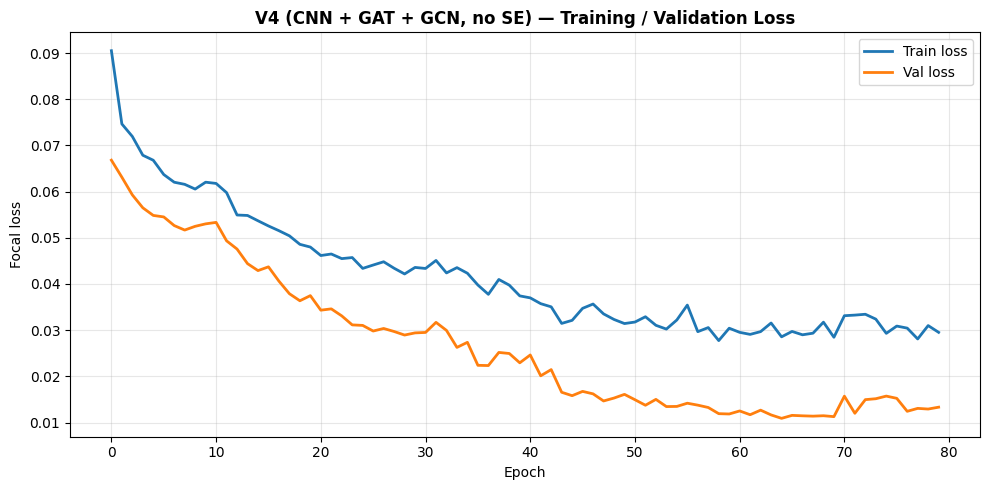

Saved: <repo>/results\Ablation_V4\V4_Loss_Curve.png


In [9]:
plt.figure(figsize=(10,5))
plt.plot(history['train_loss'], label='Train loss', linewidth=2)
plt.plot(history['val_loss'],   label='Val loss',   linewidth=2)
plt.xlabel('Epoch'); plt.ylabel('Focal loss')
plt.title('V4 (CNN + GAT + GCN, no SE) — Training / Validation Loss', fontweight='bold')
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout()
save_p = os.path.join(CONFIG['output_dir'], 'V4_Loss_Curve.png')
plt.savefig(save_p, dpi=600, bbox_inches='tight'); plt.show()
print('Saved:', save_p)


## CELL 7B — Training Accuracy Curve

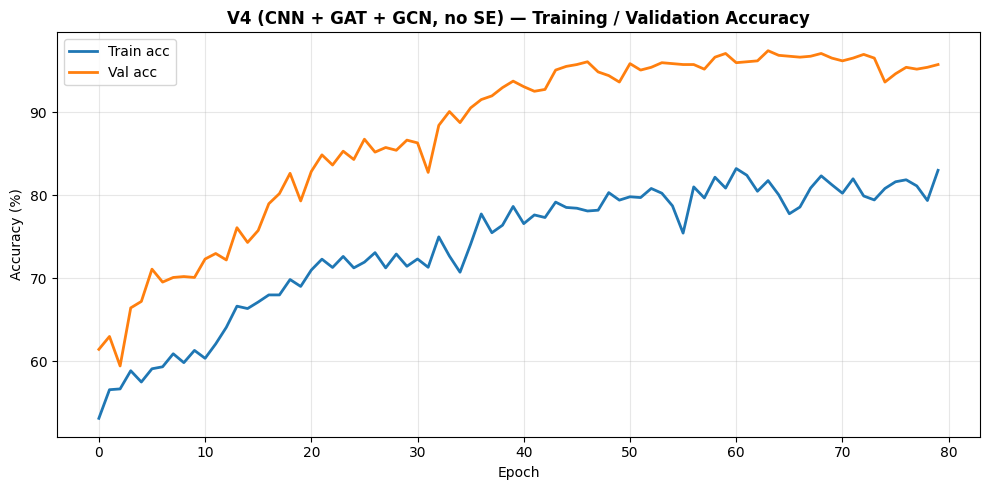

Saved: <repo>/results\Ablation_V4\V4_Accuracy_Curve.png


In [10]:
plt.figure(figsize=(10,5))
plt.plot([a*100 for a in history['train_acc']], label='Train acc', linewidth=2)
plt.plot([a*100 for a in history['val_acc']],   label='Val acc',   linewidth=2)
plt.xlabel('Epoch'); plt.ylabel('Accuracy (%)')
plt.title('V4 (CNN + GAT + GCN, no SE) — Training / Validation Accuracy', fontweight='bold')
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout()
save_p = os.path.join(CONFIG['output_dir'], 'V4_Accuracy_Curve.png')
plt.savefig(save_p, dpi=600, bbox_inches='tight'); plt.show()
print('Saved:', save_p)


## CELL 7C — Validation AUC-ROC Curve

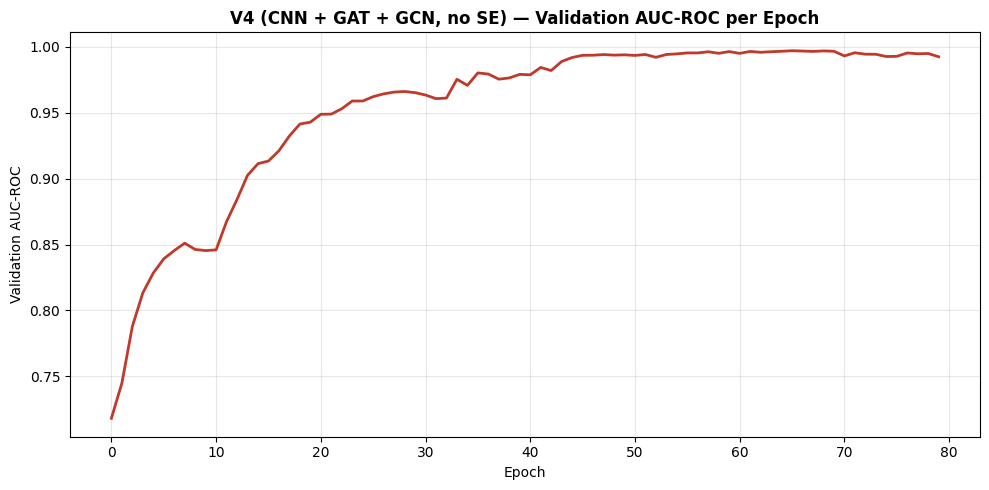

Saved: <repo>/results\Ablation_V4\V4_Validation_AUC_Curve.png


In [11]:
plt.figure(figsize=(10,5))
plt.plot(history['val_auc'], color='#c0392b', linewidth=2)
plt.xlabel('Epoch'); plt.ylabel('Validation AUC-ROC')
plt.title('V4 (CNN + GAT + GCN, no SE) — Validation AUC-ROC per Epoch', fontweight='bold')
plt.grid(alpha=0.3); plt.tight_layout()
save_p = os.path.join(CONFIG['output_dir'], 'V4_Validation_AUC_Curve.png')
plt.savefig(save_p, dpi=600, bbox_inches='tight'); plt.show()
print('Saved:', save_p)


## CELL 7D — Confusion Matrix (TTA×5)

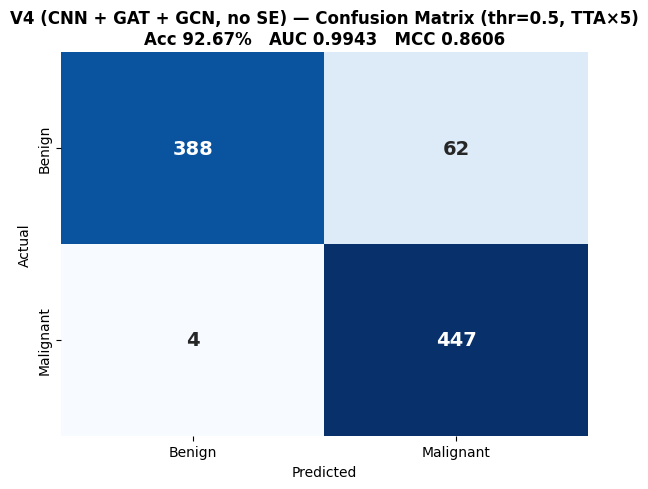

Saved: <repo>/results\Ablation_V4\V4_Confusion_Matrix.png


In [12]:
cm = confusion_matrix(all_labels_test, all_preds_test)
plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES,
            cbar=False, annot_kws={'size':14, 'weight':'bold'})
plt.xlabel('Predicted'); plt.ylabel('Actual')
plt.title(f'V4 (CNN + GAT + GCN, no SE) — Confusion Matrix (thr=0.5, TTA×5)\n'
          f'Acc {acc_tta*100:.2f}%   AUC {auc_tta:.4f}   MCC {mcc_tta:.4f}',
          fontweight='bold')
plt.tight_layout()
save_p = os.path.join(CONFIG['output_dir'], 'V4_Confusion_Matrix.png')
plt.savefig(save_p, dpi=600, bbox_inches='tight'); plt.show()
print('Saved:', save_p)


## CELL 7E — ROC Curve

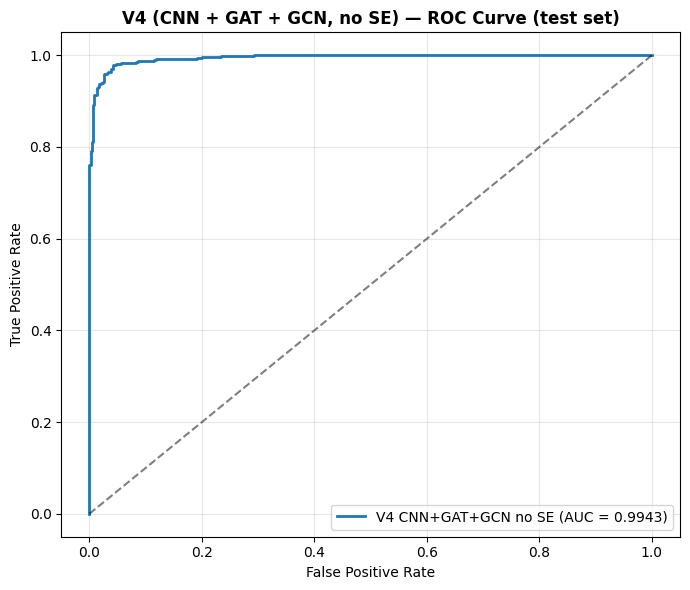

Saved: <repo>/results\Ablation_V4\V4_ROC_Curve.png


In [13]:
plt.figure(figsize=(7,6))
plt.plot(v4_fpr_saved, v4_tpr_saved, lw=2, label=f'V4 CNN+GAT+GCN no SE (AUC = {v4_auc_saved:.4f})')
plt.plot([0,1],[0,1], 'k--', alpha=0.5)
plt.xlabel('False Positive Rate'); plt.ylabel('True Positive Rate')
plt.title('V4 (CNN + GAT + GCN, no SE) — ROC Curve (test set)', fontweight='bold')
plt.legend(loc='lower right'); plt.grid(alpha=0.3); plt.tight_layout()
save_p = os.path.join(CONFIG['output_dir'], 'V4_ROC_Curve.png')
plt.savefig(save_p, dpi=600, bbox_inches='tight'); plt.show()
print('Saved:', save_p)


## CELL 7F — Precision-Recall Curve

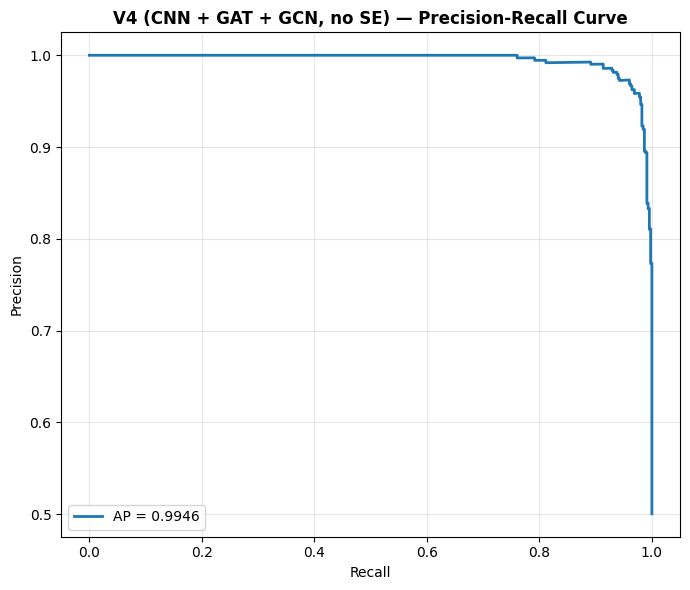

Saved: <repo>/results\Ablation_V4\V4_PR_Curve.png


In [14]:
prec, rec, _ = precision_recall_curve(all_labels_test, all_probs_test)
ap = average_precision_score(all_labels_test, all_probs_test)
plt.figure(figsize=(7,6))
plt.plot(rec, prec, lw=2, label=f'AP = {ap:.4f}')
plt.xlabel('Recall'); plt.ylabel('Precision')
plt.title('V4 (CNN + GAT + GCN, no SE) — Precision-Recall Curve', fontweight='bold')
plt.legend(loc='lower left'); plt.grid(alpha=0.3); plt.tight_layout()
save_p = os.path.join(CONFIG['output_dir'], 'V4_PR_Curve.png')
plt.savefig(save_p, dpi=600, bbox_inches='tight'); plt.show()
print('Saved:', save_p)


## CELL 8 — Final Performance Summary

In [15]:
print('=' * 60)
print(f'  V4 (CNN + GAT + GCN, no SE) — Final Performance')
print('=' * 60)
print(f'  Test accuracy (TTA×5) : {acc_tta*100:.2f}%')
print(f'  Test AUC-ROC          : {auc_tta:.4f}')
print(f'  MCC                   : {mcc_tta:.4f}')
print(f'  F1                    : {f1_tta:.4f}')
print(f'  Sensitivity           : {sens_tta*100:.2f}%')
print(f'  Specificity           : {spec_tta*100:.2f}%')
print(f'  Best val AUC (epoch)  : {ckpt["best_auc"]:.4f}  (epoch {ckpt["epoch"]})')
print()
print('  Design summary:')
print(f'    Backbone         : EfficientNet-B4 (blocks 0-4 frozen, 5-7 tuned)')
print(f'    CNN proj dim     : {CONFIG["cnn_proj_dim"]}')
print(f'    GAT branch       : 2 layers × {CONFIG["gat_heads"]} heads, hidden {CONFIG["gat_hidden_dim"]}')
print(f'    GCN branch       : 3-layer, hidden {CONFIG["gcn_hidden_dim"]} -> 128 -> 64')
print(f'    Fusion           : concat 512 + 256 + 64 = 832   (NO SE gate)')
print(f'    Head hidden dim  : {CONFIG["head_hidden_dim"]}')
print(f'    Epochs / patience: {CONFIG["num_epochs"]} / {CONFIG["patience"]}   (matched)')
print()
print('  KEY COMPARISON: V4 vs Hybrid (V5) = pure SE-gate effect')
print('  Hybrid retrained non-TTA accuracy: 98.34%')
print(f'  V4 non-TTA accuracy: (see Cell 6B output above)')
print()
print('  All plots saved as PNG (600 DPI) in:', CONFIG['output_dir'])
print('=' * 60)


  V4 (CNN + GAT + GCN, no SE) — Final Performance
  Test accuracy (TTA×5) : 92.67%
  Test AUC-ROC          : 0.9943
  MCC                   : 0.8606
  F1                    : 0.9313
  Sensitivity           : 99.11%
  Specificity           : 86.22%
  Best val AUC (epoch)  : 0.9968  (epoch 66)

  Design summary:
    Backbone         : EfficientNet-B4 (blocks 0-4 frozen, 5-7 tuned)
    CNN proj dim     : 512
    GAT branch       : 2 layers × 4 heads, hidden 256
    GCN branch       : 3-layer, hidden 256 -> 128 -> 64
    Fusion           : concat 512 + 256 + 64 = 832   (NO SE gate)
    Head hidden dim  : 128
    Epochs / patience: 80 / 15   (matched)

  KEY COMPARISON: V4 vs Hybrid (V5) = pure SE-gate effect
  Hybrid retrained non-TTA accuracy: 98.34%
  V4 non-TTA accuracy: (see Cell 6B output above)

  All plots saved as PNG (600 DPI) in: <repo>/results\Ablation_V4
